<a href="https://colab.research.google.com/github/Shahad-Hossain/nasa-image-enhancement/blob/main/Homework_10_SOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
from PIL import ImageFilter
import math
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import glob
from sklearn.svm import LinearSVC

In [ ]:
input = "cropped_soil.jpg"
try:
    img = Image.open(input).convert('L') # Convert to RGB to ensure consistent 3-channel access
except FileNotFoundError:
    print(f"Error: The file '{input}' was not found.")
    exit()

pixels = img.load()

width, height = img.size

print(str(width) + " " + str(height))

img.save("grayscaled.jpg")

170 170


In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
rightGCMM = [[0 for i in range(256)] for i in range(256)]
downGCMM = [[0 for i in range(256)] for i in range(256)]
leftGCMM = [[0 for i in range(256)] for i in range(256)]
topGCMM = [[0 for i in range(256)] for i in range(256)]

for i in range(width - 1):
  for j in range(height):
    rightGCMM[pixels[i, j]][pixels[i + 1, j]] += 1

for i in range(width):
  for j in range(height - 1):
    downGCMM[pixels[i, j]][pixels[i, j + 1]] += 1

for i in range(1, width):
  for j in range(height):
    leftGCMM[pixels[i, j]][pixels[i - 1, j]] += 1

for i in range(width):
  for j in range(1, height):
    topGCMM[pixels[i, j]][pixels[i, j - 1]] += 1

print(max(max(topGCMM)))

tempImg = Image.new("L", (256, 256))
tempPixels = tempImg.load()
for i in range(256):
  for j in range(256):
    tempPixels[i, j] = int((rightGCMM[i][j] / 312) * 256)

tempImg1 = Image.new("L", (256, 256))
tempPixels1 = tempImg1.load()
for i in range(256):
  for j in range(256):
    tempPixels1[i, j] = int((downGCMM[i][j] / 227) * 256)

tempImg2 = Image.new("L", (256, 256))
tempPixels2 = tempImg2.load()
for i in range(256):
  for j in range(256):
    tempPixels2[i, j] = int((leftGCMM[i][j] / 246) * 256)

tempImg3 = Image.new("L", (256, 256))
tempPixels3 = tempImg3.load()
for i in range(256):
  for j in range(256):
    tempPixels3[i, j] = int((topGCMM[i][j] / 227) * 256)

tempImg.save("gay.jpg")
tempImg1.save("gay1.jpg")
tempImg2.save("gay2.jpg")
tempImg3.save("gay3.jpg")

227


In [ ]:
avgGCMM = [[0 for i in range(256)] for i in range(256)]

for i in range(256):
  for j in range(256):
    avgGCMM[i][j] = int((rightGCMM[i][j] + downGCMM[i][j] + leftGCMM[i][j] + topGCMM[i][j]) / 4)

tempImg4 = Image.new("L", (256, 256))
tempPixels4 = tempImg4.load()
for i in range(256):
  for j in range(256):
    tempPixels4[i, j] = int((avgGCMM[i][j] / 114) * 256)

tempImg4.save("finaleGay.jpg")

In [ ]:
compressSize = 8

compressedGCMM = [[0 for i in range(compressSize)] for i in range(compressSize)]

for i in range(compressSize):
  for j in range(compressSize):
    avg = 0
    for k in range((256 // compressSize) * i, (256 // compressSize) * (i + 1)):
      for l in range((256 // compressSize) * j, (256 // compressSize) * (j + 1)):
        avg += avgGCMM[k][l]

    avg /= (256 // compressSize) * (256 // compressSize)

    compressedGCMM[i][j] = avg

tempImg5 = Image.new("L", (compressSize, compressSize))
tempPixels5 = tempImg5.load()
for i in range(compressSize):
  for j in range(compressSize):
    tempPixels5[i, j] = int((compressedGCMM[i][j] / max(max(compressedGCMM))) * 256)

tempImg5.save("compressedFinaleGay.jpg")

In [ ]:
compressSize = 8
windowSize = 5

conStre = Image.new("L", (width, height))
conStrePixels = conStre.load()


for w in range(width):
  for h in range(height):
    rightGCMM = [[0 for i in range(256)] for i in range(256)]
    downGCMM = [[0 for i in range(256)] for i in range(256)]
    leftGCMM = [[0 for i in range(256)] for i in range(256)]
    topGCMM = [[0 for i in range(256)] for i in range(256)]

    for i in range(max(0, w - (windowSize // 2)), min(width, w + ((windowSize - 1) // 2)) - 1):
      for j in range(max(0, h - (windowSize // 2)), min(height, h + ((windowSize - 1) // 2))):
        rightGCMM[pixels[i, j]][pixels[i + 1, j]] += 1

    for i in range(max(0, w - (windowSize // 2)), min(width, w + ((windowSize - 1) // 2))):
      for j in range(max(0, h - (windowSize // 2)), min(height, h + ((windowSize - 1) // 2)) - 1):
        downGCMM[pixels[i, j]][pixels[i, j + 1]] += 1

    for i in range(max(1, w - (windowSize // 2) + 1), min(width, w + ((windowSize - 1) // 2))):
      for j in range(max(0, h - (windowSize // 2)), min(height, h + ((windowSize - 1) // 2))):
        leftGCMM[pixels[i, j]][pixels[i - 1, j]] += 1

    for i in range(max(0, w - (windowSize // 2)), min(width, w + ((windowSize - 1) // 2))):
      for j in range(max(1, h - (windowSize // 2)), min(height, h + ((windowSize - 1) // 2))):
        topGCMM[pixels[i, j]][pixels[i, j - 1]] += 1

    avgGCMM = [[0 for i in range(256)] for i in range(256)]

    for i in range(256):
      for j in range(256):
        avgGCMM[i][j] = int((rightGCMM[i][j] + downGCMM[i][j] + leftGCMM[i][j] + topGCMM[i][j]) / 4)

    compressedGCMM = [[0 for i in range(compressSize)] for i in range(compressSize)]

    for i in range(compressSize):
      for j in range(compressSize):
        avg = 0
        for k in range((256 // compressSize) * i, (256 // compressSize) * (i + 1)):
          for l in range((256 // compressSize) * j, (256 // compressSize) * (j + 1)):
            avg += avgGCMM[k][l]

        compressedGCMM[i][j] = avg

    contrastStretch = 0
    for i in range(compressSize):
      for j in range(compressSize):
        contrastStretch += compressedGCMM[i][j] * (i - j) ** 2

    conStrePixels[w, h] = contrastStretch


conStre.save("finny.jpg")

KeyboardInterrupt: 

In [ ]:
from PIL import Image
import numpy as np

compressSize = 8
windowSize = 5
half = windowSize // 2

levels = 32  # 🔥 BIG SPEED BOOST (instead of 256)

img = np.array(img, dtype=np.int32)  # convert FIRST

img = (img * levels) // 256

conStre = Image.new("L", (width, height))
conStrePixels = conStre.load()

for w in range(width):
    for h in range(height):

        # window bounds
        x0 = max(0, w - half)
        x1 = min(width, w + half + 1)
        y0 = max(0, h - half)
        y1 = min(height, h + half + 1)

        patch = img[x0:x1, y0:y1]

        # skip tiny borders
        if patch.shape[0] < 2 or patch.shape[1] < 2:
            conStrePixels[w, h] = 0
            continue

        # build GLCM (ONLY RIGHT + DOWN → enough, removes 2 loops)
        glcm = np.zeros((levels, levels))

        # RIGHT neighbors
        glcm += np.bincount(
            patch[:, :-1].ravel() * levels + patch[:, 1:].ravel(),
            minlength=levels * levels
        ).reshape(levels, levels)

        # DOWN neighbors
        glcm += np.bincount(
            patch[:-1, :].ravel() * levels + patch[1:, :].ravel(),
            minlength=levels * levels
        ).reshape(levels, levels)

        # normalize
        glcm = glcm / (glcm.sum() + 1e-9)

        # FAST contrast (vectorized Haralick formula)
        i = np.arange(levels)
        I, J = np.meshgrid(i, i)

        contrast = np.sum(glcm * (I - J) ** 2)

        conStrePixels[w, h] = int(contrast * 255)

conStre.save("finny.jpg")

In [ ]:
import numpy as np
from PIL import Image

def generate_glcm_contrast(image_path, output_path, window_size=7, levels=16):
    # 1. Load and convert to grayscale/numpy array immediately
    # We use int32 to prevent the "uint8 overflow" error during math operations
    img_raw = Image.open(image_path).convert('L')
    img = np.array(img_raw, dtype=np.int32)

    # 2. Downsample gray levels (Essential for speed and stability)
    # This maps 0-255 into 0-(levels-1)
    img = (img * levels) // 256

    width, height = img.shape
    half = window_size // 2

    # Create empty output image buffer
    contrast_map = np.zeros((width, height), dtype=np.float32)

    # 3. Sliding Window logic
    # We skip the edges (half) to avoid partial window artifacts (the black strips)
    for w in range(half, width - half):
        for h in range(half, height - half):

            # Extract local patch
            window = img[w-half : w+half+1, h-half : h+half+1]

            # Initialize local GLCM for this specific window
            glcm = np.zeros((levels, levels), dtype=np.float32)

            # Fill GLCM (Horizontal relationship: pixel and its immediate right neighbor)
            for i in range(window.shape[0]):
                for j in range(window.shape[1] - 1):
                    p1 = window[i, j]
                    p2 = window[i, j+1]
                    glcm[p1, p2] += 1

            # 4. NORMALIZATION
            # This turns raw counts into probabilities, preventing "noise explosion"
            glcm_sum = np.sum(glcm)
            if glcm_sum > 0:
                glcm /= glcm_sum

            # 5. Calculate Contrast
            # Formula: sum( P(i,j) * (i-j)^2 )
            contrast_val = 0
            for i in range(levels):
                for j in range(levels):
                    if glcm[i, j] > 0:
                        contrast_val += glcm[i, j] ** 2#* (i - j)**2

            contrast_map[w, h] = contrast_val

    # 6. Final Scaling for visibility
    # This normalizes the result back to 0-255 for the final image
    max_c = np.max(contrast_map)
    if max_c > 0:
        contrast_map = (contrast_map / max_c) * 255

    final_img = Image.fromarray(contrast_map.astype(np.uint8))
    final_img.save(output_path)
    print(f"Analysis complete. Saved to {output_path}")

# Run the analysis
generate_glcm_contrast("image_10.jpg", "mars_texture_map.jpg", 7, 8)

Analysis complete. Saved to mars_texture_map.jpg


In [ ]:
def get_lbp_pixel(img, x, y):
    """
    Compares a pixel to its 8 neighbors and returns the LBP code.
    """
    center = img[x, y]
    val_ar = []

    # Top-left, Top, Top-right, Right, Bottom-right, Bottom, Bottom-left, Left
    neighbors = [
        (x-1, y-1), (x-1, y), (x-1, y+1),
        (x, y+1), (x+1, y+1), (x+1, y),
        (x+1, y-1), (x, y-1)
    ]

    for nx, ny in neighbors:
        if img[nx, ny] >= center:
            val_ar.append(1)
        else:
            val_ar.append(0)

    # Convert binary list to decimal
    res = 0
    for i in range(len(val_ar)):
        res += val_ar[i] * (2 ** i)
    return res

def generate_lbp(image_path, output_path):
    # 1. Load image and convert to grayscale
    img_raw = Image.open(image_path).convert('L')
    img = np.array(img_raw)

    width, height = img.shape
    # Create an empty array for the LBP result
    lbp_img = np.zeros((width, height), dtype=np.uint8)

    # 2. Iterate through pixels (skipping the 1-pixel border)
    for i in range(1, width - 1):
        for j in range(1, height - 1):
            lbp_img[i, j] = get_lbp_pixel(img, i, j)

    # 3. Save the result
    final_img = Image.fromarray(lbp_img)
    final_img.save(output_path)
    print(f"LBP processing complete. Saved to {output_path}")

# Run it on your original image
generate_lbp("cropped_soil.jpg", "mars_lbp_result.jpg")

LBP processing complete. Saved to mars_lbp_result.jpg


In [ ]:
def get_lbp_pixel(img, x, y):
    """
    Compares a pixel to its 8 neighbors and returns the LBP code.
    """
    center = img[x, y]
    val_ar = []

    # Top-left, Top, Top-right, Right, Bottom-right, Bottom, Bottom-left, Left
    neighbors = [
        (x-1, y-1), (x-1, y), (x-1, y+1),
        (x, y+1), (x+1, y+1), (x+1, y),
        (x+1, y-1), (x, y-1)
    ]
    max = -1
    min = 256
    for nx, ny in neighbors:
        if img[nx, ny] > max:
            max = img[nx, ny]

        if img[nx, ny] < min:
            min = img[nx, ny]

    for nx, ny in neighbors:
        if img[nx, ny] >= ((max + min) // 2):
            val_ar.append(1)
        else:
            val_ar.append(0)

    # Convert binary list to decimal
    res = 0
    for i in range(len(val_ar)):
        res += val_ar[i] * (2 ** i)
    return res

def generate_lbp(image_path, output_path):
    # 1. Load image and convert to grayscale
    img_raw = Image.open(image_path).convert('L')
    img = np.array(img_raw)

    width, height = img.shape
    # Create an empty array for the LBP result
    lbp_img = np.zeros((width, height), dtype=np.uint8)

    # 2. Iterate through pixels (skipping the 1-pixel border)
    for i in range(1, width - 1):
        for j in range(1, height - 1):
            lbp_img[i, j] = get_lbp_pixel(img, i, j)

    # 3. Save the result
    final_img = Image.fromarray(lbp_img)
    final_img.save(output_path)
    print(f"LBP processing complete. Saved to {output_path}")

# Run it on your original image
generate_lbp("cropped_soil.jpg", "mars_lbp_result.jpg")

/tmp/ipykernel_11355/2496852908.py:24: RuntimeWarning: overflow encountered in scalar add
  if img[nx, ny] >= ((max + min) // 2):


LBP processing complete. Saved to mars_lbp_result.jpg


In [ ]:
def showHistogramBar(img, midpoint=None, threshold=None):
    width, height = img.size
    pixels = img.load()

    # Build histogram
    hist = [0] * 256
    for i in range(width):
        for j in range(height):
            hist[pixels[i, j]] += 1

    # Plot as bar graph
    plt.figure(figsize=(10, 5))
    plt.bar(range(256), hist, width=1.0)

    # Optional markers
    if midpoint is not None:
        plt.axvline(midpoint, color='orange', linestyle='--', label=f"Midpoint ({midpoint})")

    if threshold is not None:
        plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold})")

    plt.title("Grayscale Histogram (Bar Graph)")
    plt.xlabel("Pixel Intensity (0–255)")
    plt.ylabel("Frequency")
    plt.xlim([0, 255])

    if midpoint is not None or threshold is not None:
        plt.legend()

    plt.grid(True, axis='y')
    plt.show()

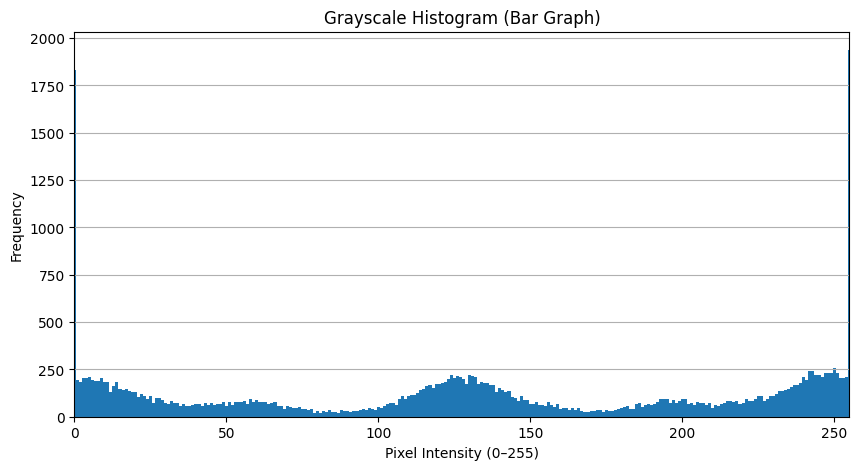

In [ ]:
showHistogramBar(Image.open("mars_lbp_result.jpg"))

In [ ]:
import numpy as np
from PIL import Image
from skimage.feature import local_binary_pattern

def calculate_lbp_feature_vector(image_path, radius=1, n_points=8):
    """
    Calculates LBP with a variable window size.
    radius: The distance from center to neighbor (increases window size).
    n_points: Number of points to sample (usually 8 * radius).
    """
    # 1. Load and Grayscale
    img = np.array(Image.open(image_path).convert('L'))

    # 2. Calculate LBP using a variable radius
    # 'uniform' method is recommended for variable radii to keep the vector size manageable
    lbp = local_binary_pattern(img, n_points, radius, method='uniform')

    # 3. Calculate Histogram
    # When using 'uniform', the number of possible values is n_points + 2
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))

    # 4. Normalize
    hist = hist.astype("float32")
    hist /= (hist.sum() + 1e-7)

    return hist

# Example usage:
# Large window (Radius 3, 24 points)
# vector = calculate_lbp_feature_vector("mars_soil.jpg", radius=3, n_points=24)

print(calculate_lbp_feature_vector("cropped_soil.jpg"))

[0.06442907 0.08903114 0.07577854 0.1116955  0.1417647  0.13574395
 0.09460208 0.0816955  0.0715917  0.13366783]


In [ ]:
import numpy as np
from PIL import Image
from skimage.feature import local_binary_pattern

def calculate_lbp_feature_vector(image_path, radius=1, n_points=8):
    img = np.array(Image.open(image_path).convert('L'))

    lbp = local_binary_pattern(img, n_points, radius, method='uniform')

    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))

    hist = hist.astype("float32")
    hist /= (hist.sum() + 1e-7)

    return hist

print(calculate_lbp_feature_vector("cropped_soil.jpg"))